# NEPSE Next-Day Forecasting: Walk-Forward Evaluation and Backtest (v3)

Runs in **Google Colab** or locally. Self-contained.

**Contents**
1. Install, imports, settings, reproducibility
2. Data download
3. Features (no leakage, target = next-day return)
4. Helpers: metrics, folds, models, LSTM, backtest
5. Main loop: walk-forward evaluation per stock
6. Results: skill score, direction accuracy, final holdout
7. Backtest with NEPSE trading costs
8. Feature importance
9. Conclusion (auto-generated) and exported files
10. Save and download

**What is new in v3**
- **Walk-forward validation:** 5 expanding-window folds instead of one split.
- **Return target:** models predict the next-day % change. Price = today x (1 + return).
- **Skill score:** `1 - model RMSE / naive RMSE`. Above 0 means better than "tomorrow = today".
- **Direction accuracy** counts only days where the price moved.
- **Backtest** with brokerage, SEBON fee and capital gains tax, against buy-and-hold.
- **Permutation feature importance**, auto-generated conclusion, CSV exports.

## 1. Install, imports, settings

In [1]:
!pip install -q xgboost scikit-learn joblib requests matplotlib

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import base64
import logging
import platform
import shutil
import time
import warnings
import zipfile
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
import xgboost as xgb
from IPython.display import HTML, display
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore")
logging.getLogger("absl").setLevel(logging.ERROR)

try:
    import tensorflow as tf
    from tensorflow.keras.callbacks import EarlyStopping
    from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
    from tensorflow.keras.models import Sequential
    tf.get_logger().setLevel("ERROR")
    RUN_LSTM = True
except ImportError:
    RUN_LSTM = False
    print("TensorFlow not found. LSTM will be skipped.")

# ---- settings ----
SYMBOLS = ["NABIL", "NICA", "GBIME", "SCB", "SHIVM"]
N_FOLDS = 5                  # walk-forward folds
FIRST_TRAIN_FRACTION = 0.5   # first fold trains on the first 50% of rows
SEQ_LENGTH = 60              # LSTM window
LSTM_EPOCHS = 50
RANDOM_SEED = 42

# Backtest. Rates vary by broker and trade size. Verify current NEPSE rates.
BACKTEST_THRESHOLD = 0.0     # hold only if predicted return (%) is above this
COST_PER_SIDE = 0.00415      # 0.40% brokerage (small trades) + 0.015% SEBON fee, per buy and per sell
CGT_RATE = 0.075             # capital gains tax on profit, held under 365 days (5% if longer)

NAIVE = "Naive (today = tomorrow)"
LIN, RF, XGB, LSTM_NAME = "Linear Regression", "Random Forest", "XGBoost", "LSTM"

DATA_DIR, MODEL_DIR, SCALER_DIR = Path("data"), Path("models"), Path("scalers")
for folder in (DATA_DIR, MODEL_DIR, SCALER_DIR):
    folder.mkdir(exist_ok=True)

np.random.seed(RANDOM_SEED)
if RUN_LSTM:
    tf.random.set_seed(RANDOM_SEED)

# ---- reproducibility record ----
print("Run date     :", date.today())
print("Python       :", platform.python_version())
print("pandas/numpy :", pd.__version__, "/", np.__version__)
print("scikit-learn :", sklearn.__version__, "| xgboost:", xgb.__version__)
print("TensorFlow   :", tf.__version__ if RUN_LSTM else "not installed")
print("Seed         :", RANDOM_SEED, "| folds:", N_FOLDS, "| LSTM epochs:", LSTM_EPOCHS)

Run date     : 2026-10-30
Python       : 3.13.16
pandas/numpy : 2.2.3 / 2.1.3
scikit-learn : 1.6.1 | xgboost: 3.4.1
TensorFlow   : 2.21.0
Seed         : 42 | folds: 5 | LSTM epochs: 50


## 2. Data download

In [3]:
def get_nepse_data(symbol, retries=3):
    url = f"https://omitnomis.github.io/ShareSansarScraper/api/history/{symbol}.json"
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=15)
            r.raise_for_status()
            data = r.json()
            df = pd.DataFrame(data["rows"], columns=data["cols"])
            df = df.rename(columns={"d": "Date", "o": "Open", "h": "High",
                                    "l": "Low", "c": "Close", "vol": "Volume"})
            break
        except (requests.RequestException, ValueError, KeyError) as exc:
            last_error = exc
            time.sleep(attempt)
    else:
        local = DATA_DIR / f"{symbol}.csv"
        if not local.exists():
            raise RuntimeError(f"{symbol}: download failed ({last_error}) and {local} not found")
        print(f"  Download failed ({last_error}). Using {local}")
        df = pd.read_csv(local)

    df = df[["Date", "Open", "High", "Low", "Close", "Volume"]].copy()
    df["Date"] = pd.to_datetime(df["Date"])
    for col in ["Open", "High", "Low", "Close", "Volume"]:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", ""), errors="coerce")
    df = df.dropna().drop_duplicates("Date").sort_values("Date").reset_index(drop=True)
    df.to_csv(DATA_DIR / f"{symbol}.csv", index=False)  # also used to load the API database
    return df

## 3. Features (no leakage)

Row *t* uses data up to **today**. The target is **tomorrow's return in percent**:
`(Close_t+1 / Close_t - 1) x 100`. Predicting returns instead of prices avoids the
extrapolation failure seen on SHIVM, where tree models cannot output prices outside the training range.

In [4]:
def compute_rsi(close, period=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = (-delta).clip(lower=0)
    avg_gain = gain.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()
    return 100 - 100 / (1 + avg_gain / avg_loss)


def add_features(df):
    df = df.copy()
    close = df["Close"]
    df["Open-Close"]     = df["Open"] - close
    df["High-Low"]       = df["High"] - df["Low"]
    df["Percent Change"] = close.pct_change() * 100
    df["5 Day MA"]       = close.rolling(5).mean()
    df["10 Day MA"]      = close.rolling(10).mean()
    df["EMA_10"]         = close.ewm(span=10, adjust=False).mean()
    df["EMA_20"]         = close.ewm(span=20, adjust=False).mean()
    df["Volatility"]     = df["High"].rolling(10).std()
    df["RSI"]            = compute_rsi(close)
    df["Close_lag1"]     = close.shift(1)
    df["Close_lag2"]     = close.shift(2)
    df["Target"]         = close.shift(-1)                       # tomorrow's close
    df["Target Return"]  = (df["Target"] / close - 1) * 100      # tomorrow's return, %
    df["Target Date"]    = df["Date"].shift(-1)
    return df


# Same names and order as the FastAPI project.
FEATURES = [
    "Open-Close", "High-Low", "Percent Change", "5 Day MA", "10 Day MA",
    "EMA_10", "EMA_20", "Volatility", "RSI", "Close_lag1", "Close_lag2",
    "Open", "High", "Low", "Close", "Volume",
]
API_NAMES = {
    "Open-Close": "open_close", "High-Low": "high_low", "Percent Change": "pct_change",
    "5 Day MA": "ma_5", "10 Day MA": "ma_10", "EMA_10": "ema_10", "EMA_20": "ema_20",
    "Volatility": "volatility", "RSI": "rsi", "Close_lag1": "close_lag1",
    "Close_lag2": "close_lag2", "Open": "open", "High": "high", "Low": "low",
    "Close": "close", "Volume": "volume",
}

## 4. Helpers

In [5]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))


def mae(actual, predicted):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))


def to_price(today, ret_pct):
    return np.asarray(today) * (1 + np.asarray(ret_pct) / 100)


def direction_acc_moved(today, actual, predicted):
    # Only days where the price really moved. Flat days have no direction.
    moved = actual != today
    if moved.sum() == 0:
        return np.nan
    return float((np.sign(actual - today)[moved] == np.sign(predicted - today)[moved]).mean())


def up_share(today, actual):
    # Baseline: always guess "up". Share of moved days that went up.
    moved = actual != today
    return float((actual[moved] > today[moved]).mean()) if moved.sum() else np.nan


def metrics_row(name, today, actual, price_pred, naive_rmse):
    r = rmse(actual, price_pred)
    return {
        "model": name,
        "RMSE": r,
        "MAE": mae(actual, price_pred),
        "skill": 1 - r / naive_rmse,
        "dir_acc": np.nan if name == NAIVE else direction_acc_moved(today, actual, price_pred),
    }


def make_folds(n, n_folds=N_FOLDS, first_train=FIRST_TRAIN_FRACTION):
    # Expanding window. Fold k trains on all rows before its test block.
    start = int(n * first_train)
    block = (n - start) // n_folds
    assert block >= 20, "Not enough rows for walk-forward"
    folds = []
    for k in range(n_folds):
        te_start = start + k * block
        te_end = n if k == n_folds - 1 else te_start + block
        folds.append((te_start, te_start, te_end))  # (train_end, test_start, test_end)
    return folds


def fit_models(X_train, y_train):
    models = {
        LIN: make_pipeline(StandardScaler(), LinearRegression()),
        RF: RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
        XGB: xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5,
                              random_state=RANDOM_SEED, verbosity=0),
    }
    for model in models.values():
        model.fit(X_train, y_train)
    return models

In [6]:
def walk_forward(data):
    X, y = data[FEATURES], data["Target Return"]
    today_all, actual_all = data["Close"].to_numpy(), data["Target"].to_numpy()
    fold_rows, blocks = [], []
    last_models = None

    for k, (tr_end, te_start, te_end) in enumerate(make_folds(len(data)), start=1):
        models = fit_models(X.iloc[:tr_end], y.iloc[:tr_end])
        X_te = X.iloc[te_start:te_end]
        today, actual = today_all[te_start:te_end], actual_all[te_start:te_end]

        pred_ret = {NAIVE: np.zeros(len(today))}
        for name, m in models.items():
            pred_ret[name] = m.predict(X_te)
        price = {name: to_price(today, r) for name, r in pred_ret.items()}

        naive_rmse = rmse(actual, price[NAIVE])
        for name in price:
            fold_rows.append({"fold": k, **metrics_row(name, today, actual, price[name], naive_rmse)})

        block = pd.DataFrame({"date": data["Target Date"].iloc[te_start:te_end].to_numpy(),
                              "fold": k, "today": today, "actual": actual})
        for name in price:
            block[f"p_{name}"] = price[name]
            block[f"r_{name}"] = pred_ret[name]
        blocks.append(block)
        last_models = (models, X_te, y.iloc[te_start:te_end])

    return pd.DataFrame(fold_rows), pd.concat(blocks, ignore_index=True), last_models

In [7]:
def run_lstm_final(data, te_start, te_end):
    # Trains on rows before te_start. Predicts the final test block. Leak-free scaling.
    X, y = data[FEATURES], data["Target Return"]
    assert te_start >= SEQ_LENGTH - 1, "Not enough rows for LSTM windows"
    x_scaler = MinMaxScaler().fit(X.iloc[:te_start])
    y_scaler = StandardScaler().fit(y.iloc[:te_start].to_numpy().reshape(-1, 1))
    Xs = x_scaler.transform(X)
    ys = y_scaler.transform(y.to_numpy().reshape(-1, 1)).ravel()

    # window k ends at row k + SEQ_LENGTH - 1
    windows = np.array([Xs[i - SEQ_LENGTH + 1 : i + 1] for i in range(SEQ_LENGTH - 1, len(Xs))])
    targets = ys[SEQ_LENGTH - 1 :]
    off = SEQ_LENGTH - 1
    X_tr, y_tr = windows[: te_start - off], targets[: te_start - off]
    X_te = windows[te_start - off : te_end - off]

    model = Sequential([
        Input(shape=(SEQ_LENGTH, X.shape[1])),
        LSTM(100, return_sequences=True), Dropout(0.2),
        LSTM(50), Dropout(0.2),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mean_squared_error")
    model.fit(X_tr, y_tr, epochs=LSTM_EPOCHS, batch_size=32, validation_split=0.1,
              callbacks=[EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    pred_ret = y_scaler.inverse_transform(model.predict(X_te, verbose=0)).ravel()
    return pred_ret, model, x_scaler, y_scaler

In [8]:
def max_drawdown(curve):
    curve = np.asarray(curve)
    return float((curve / np.maximum.accumulate(curve) - 1).min())


def backtest(today, actual, position, cost=COST_PER_SIDE, cgt=CGT_RATE):
    # Long or cash (no short selling on NEPSE). Position is decided at today's close
    # and earns the return from today's close to tomorrow's close.
    ret = np.asarray(actual) / np.asarray(today) - 1
    eq_gross = eq_net = entry = 1.0
    prev, trades = 0, 0
    gross_curve, net_curve = [], []

    def sell(eq, entry):
        gain = max(eq - entry, 0.0)
        return (eq - cgt * gain) * (1 - cost)

    for r, pos in zip(ret, position):
        if prev == 1 and pos == 0:
            eq_net = sell(eq_net, entry)
        if prev == 0 and pos == 1:
            eq_net *= 1 - cost
            entry = eq_net
            trades += 1
        if pos == 1:
            eq_net *= 1 + r
            eq_gross *= 1 + r
        prev = pos
        gross_curve.append(eq_gross)
        net_curve.append(eq_net)
    if prev == 1:
        eq_net = sell(eq_net, entry)
        net_curve[-1] = eq_net

    return {
        "net_curve": np.array(net_curve), "gross_curve": np.array(gross_curve),
        "net_return": net_curve[-1] - 1, "gross_return": gross_curve[-1] - 1,
        "max_drawdown": max_drawdown(net_curve), "trades": trades,
        "time_in_market": float(np.mean(position)),
    }

## 5. Main loop: walk-forward per stock

Each fold trains on all earlier rows and tests on the next block. No shuffling.
The last fold is the **final holdout**. The LSTM is trained and tested on that fold only,
because retraining it five times per stock is slow.


  NABIL
  Rows: 910 | last date: 2026-10-29


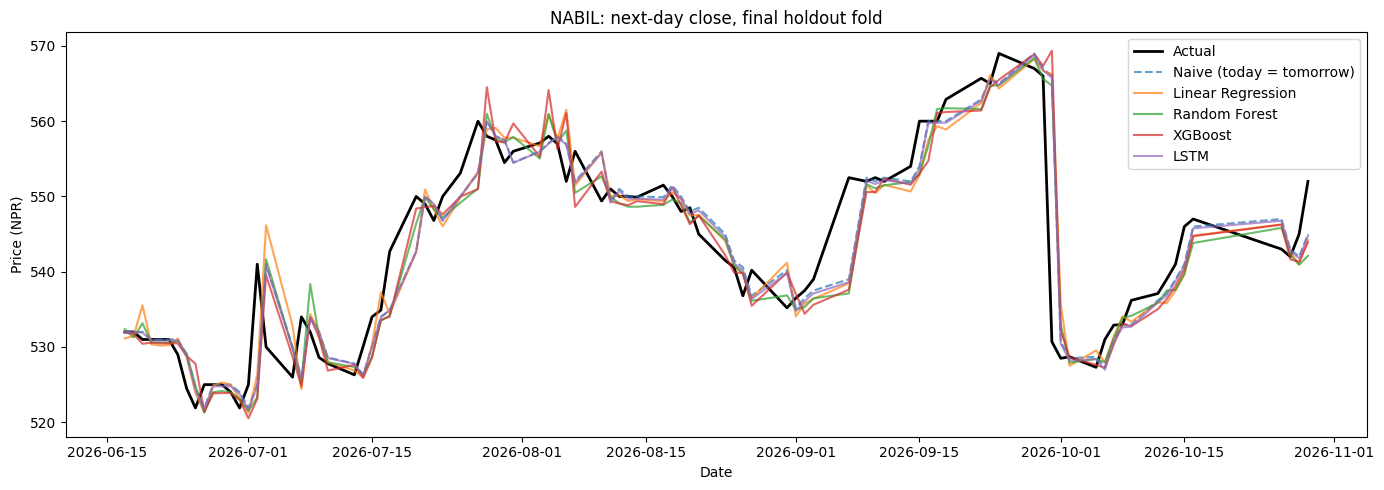

  Mean skill vs naive: {'Linear Regression': '-5.3%', 'Random Forest': '-21.0%', 'XGBoost': '-46.3%'}

  NICA
  Rows: 910 | last date: 2026-10-29


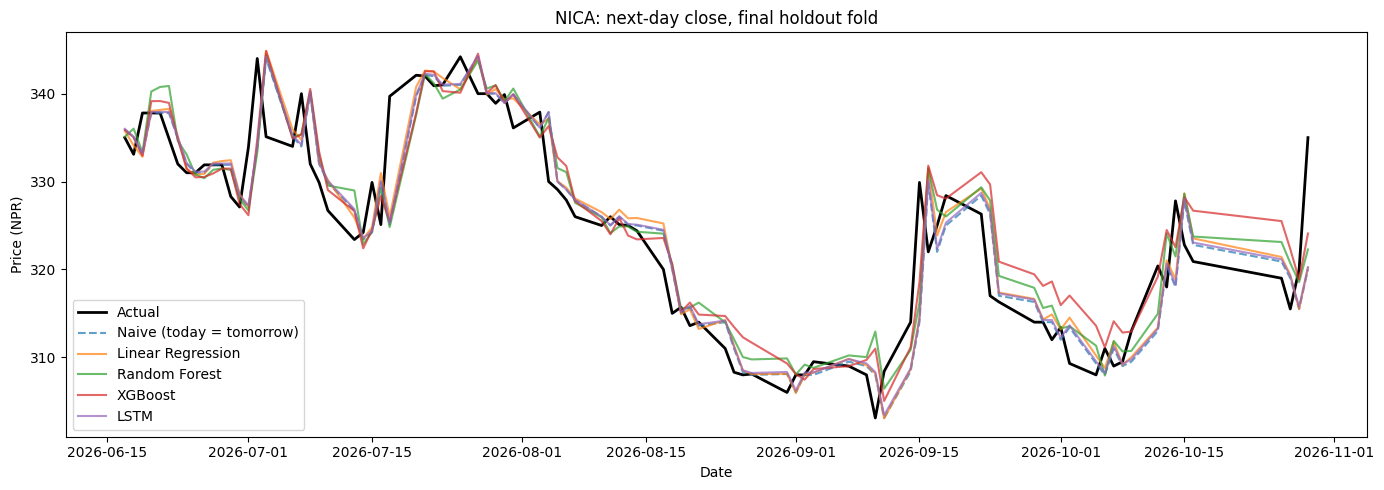

  Mean skill vs naive: {'Linear Regression': '-3.4%', 'Random Forest': '-22.1%', 'XGBoost': '-17.1%'}

  GBIME
  Rows: 910 | last date: 2026-10-29


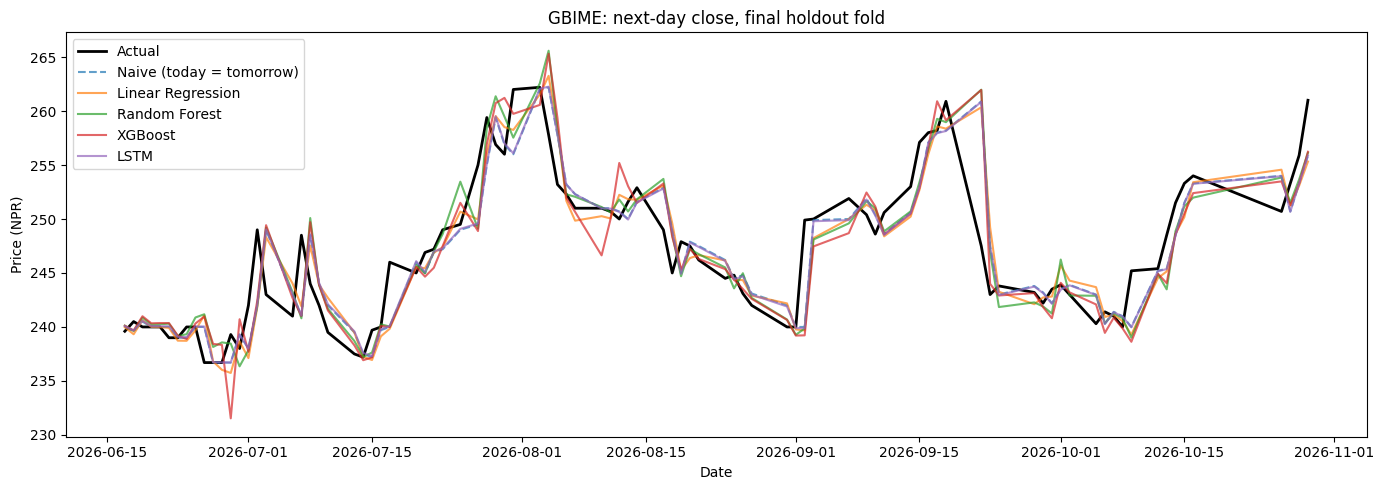

  Mean skill vs naive: {'Linear Regression': '-1.9%', 'Random Forest': '-9.4%', 'XGBoost': '-14.8%'}

  SCB
  Rows: 910 | last date: 2026-10-29


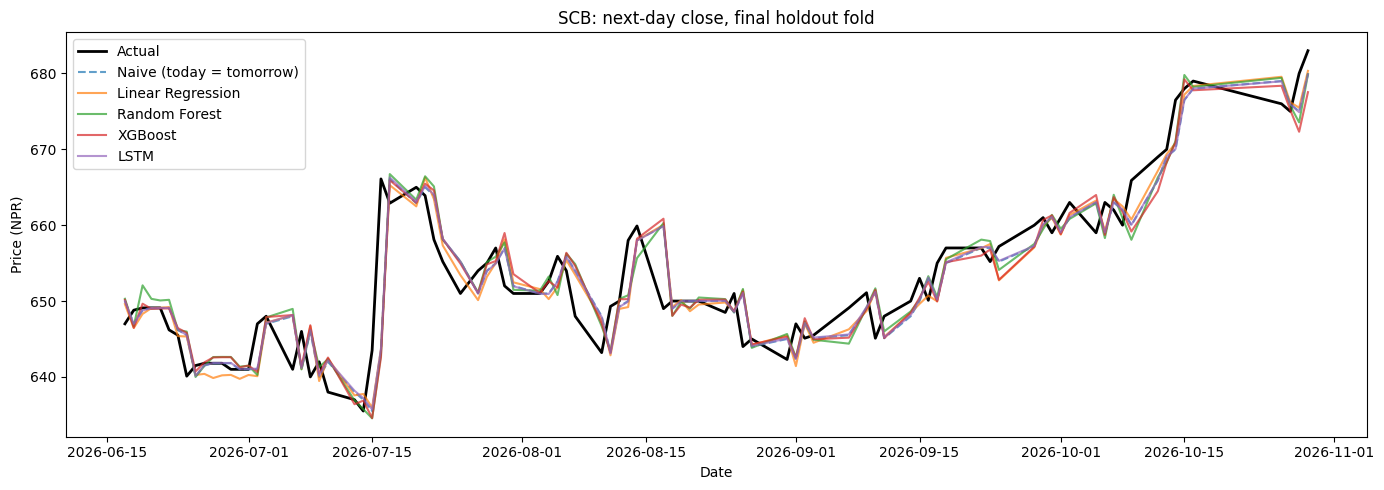

  Mean skill vs naive: {'Linear Regression': '-1.9%', 'Random Forest': '-12.9%', 'XGBoost': '-18.4%'}

  SHIVM
  Rows: 910 | last date: 2026-10-29


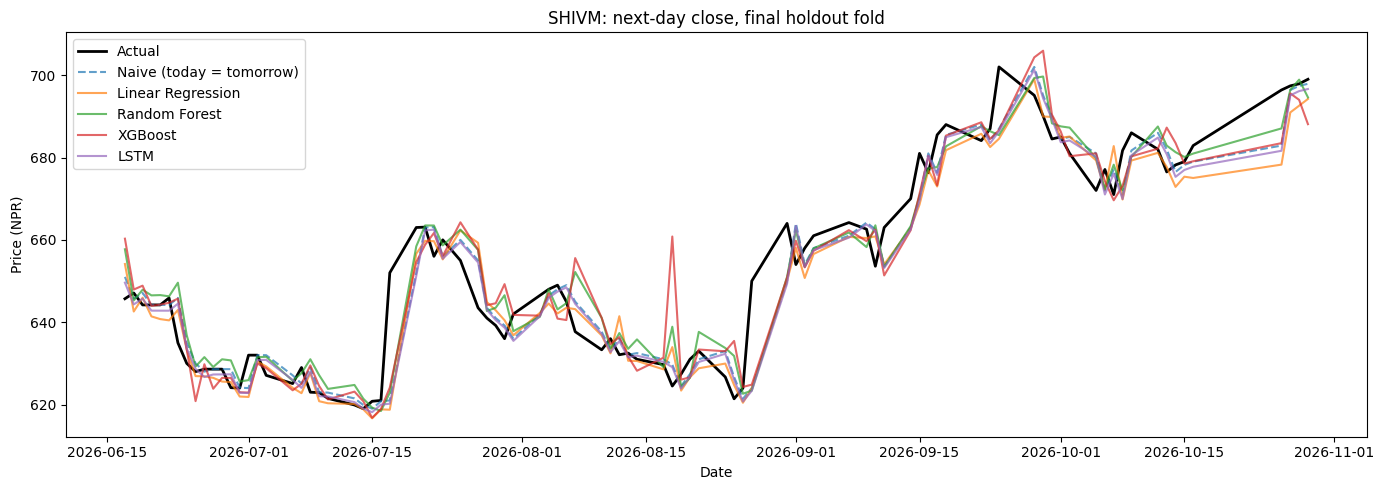

  Mean skill vs naive: {'Linear Regression': '-4.4%', 'Random Forest': '-8.1%', 'XGBoost': '-19.4%'}


In [9]:
store, bundles_info = {}, {}

for symbol in SYMBOLS:
    print(f"\n{'=' * 50}\n  {symbol}\n{'=' * 50}")
    raw = get_nepse_data(symbol)
    data = add_features(raw).dropna(subset=FEATURES + ["Target", "Target Return"]).reset_index(drop=True)
    print(f"  Rows: {len(data)} | last date: {raw['Date'].max().date()}")

    fold_df, oos, (last_models, X_last, y_last) = walk_forward(data)
    tr_end, te_start, te_end = make_folds(len(data))[-1]

    # ---- final holdout incl. LSTM ----
    final = oos[oos["fold"] == N_FOLDS]
    today, actual = final["today"].to_numpy(), final["actual"].to_numpy()
    prices = {name: final[f"p_{name}"].to_numpy() for name in (NAIVE, LIN, RF, XGB)}
    if RUN_LSTM:
        lstm_ret, lstm_model, x_scaler, y_scaler = run_lstm_final(data, te_start, te_end)
        prices[LSTM_NAME] = to_price(today, lstm_ret)
        lstm_model.save(str(MODEL_DIR / f"{symbol}_LSTM_model.keras"))
        joblib.dump({"x_scaler": x_scaler, "y_scaler": y_scaler, "features": FEATURES,
                     "seq_length": SEQ_LENGTH, "target": "return_pct"},
                    SCALER_DIR / f"{symbol}_scaler.pkl")
    naive_rmse = rmse(actual, prices[NAIVE])
    final_df = pd.DataFrame([metrics_row(n, today, actual, p, naive_rmse) for n, p in prices.items()])

    # ---- model for the FastAPI project: Linear Regression on returns, refit on all rows ----
    api_X = data[FEATURES].rename(columns=API_NAMES)
    deploy = make_pipeline(StandardScaler(), LinearRegression()).fit(api_X, data["Target Return"])
    o_actual = oos["actual"].to_numpy()
    lin_rmse, nv_rmse = rmse(o_actual, oos[f"p_{LIN}"]), rmse(o_actual, oos[f"p_{NAIVE}"])
    joblib.dump({
        "model": deploy, "features": list(api_X.columns), "target": "return_pct",
        "metrics": {"symbol": symbol, "rows": int(len(data)), "test_rows": int(len(oos)),
                    "model_rmse": round(lin_rmse, 4), "model_mae": round(mae(o_actual, oos[f"p_{LIN}"]), 4),
                    "naive_rmse": round(nv_rmse, 4), "naive_mae": round(mae(o_actual, oos[f"p_{NAIVE}"]), 4),
                    "beats_naive": bool(lin_rmse < nv_rmse)},
    }, MODEL_DIR / f"{symbol}.joblib")

    # ---- plot final holdout ----
    plt.figure(figsize=(14, 5))
    plt.plot(final["date"], actual, label="Actual", linewidth=2, color="black")
    for name, p in prices.items():
        plt.plot(final["date"], p, label=name, alpha=0.7, linestyle="--" if name == NAIVE else "-")
    plt.title(f"{symbol}: next-day close, final holdout fold")
    plt.xlabel("Date")
    plt.ylabel("Price (NPR)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(MODEL_DIR / f"{symbol}_comparison.png", dpi=150)
    plt.show()

    store[symbol] = {"data": data, "fold_df": fold_df, "oos": oos, "final_df": final_df,
                     "last_models": (last_models, X_last, y_last)}
    skill = fold_df[fold_df["model"] != NAIVE].groupby("model")["skill"].mean()
    print("  Mean skill vs naive:", {k: f"{v:+.1%}" for k, v in skill.items()})

## 6. Results

- **Skill** = `1 - model RMSE / naive RMSE`. Positive means better than "tomorrow = today".
- **Direction accuracy** uses only days where the price moved. Compare it with the "always up" baseline.

In [10]:
fold_results = pd.concat([s["fold_df"].assign(symbol=sym) for sym, s in store.items()], ignore_index=True)
models_only = fold_results[fold_results["model"] != NAIVE]

summary = models_only.groupby(["symbol", "model"]).agg(
    mean_skill=("skill", "mean"),
    std_skill=("skill", "std"),
    folds_beating_naive=("skill", lambda s: int((s > 0).sum())),
    mean_dir_acc=("dir_acc", "mean"),
)
summary["folds"] = N_FOLDS
summary.round(4)

mean_skill  std_skill  folds_beating_naive  \
symbol model                                                           
GBIME  Linear Regression     -0.0189     0.0473                    1   
       Random Forest         -0.0940     0.0237                    0   
       XGBoost               -0.1477     0.1550                    0   
NABIL  Linear Regression     -0.0527     0.0290                    0   
       Random Forest         -0.2097     0.2079                    0   
       XGBoost               -0.4631     0.4795                    0   
NICA   Linear Regression     -0.0338     0.0363                    1   
       Random Forest         -0.2214     0.2160                    0   
       XGBoost               -0.1713     0.1313                    0   
SCB    Linear Regression     -0.0193     0.0559                    2   
       Random Forest         -0.1291     0.1088                    1   
       XGBoost               -0.1840     0.1608                    0   
SHIVM  Linear Regression     -0.0438     0.0497                    1   
       Random Forest         -0.0810     0.0580                    0   
       XGBoost               -0.1935     0.0616                    0   

                          mean_dir_acc  folds  
symbol model                                   
GBIME  Linear Regression        0.5151      5  
       Random Forest            0.5293      5  
       XGBoost                  0.5026      5  
NABIL  Linear Regression        0.4572      5  
       Random Forest            0.4999      5  
       XGBoost                  0.5172      5  
NICA   Linear Regression        0.4658      5  
       Random Forest            0.4503      5  
       XGBoost                  0.4899      5  
SCB    Linear Regression        0.5211      5  
       Random Forest            0.4892      5  
       XGBoost                  0.4723      5  
SHIVM  Linear Regression        0.5353      5  
       Random Forest            0.5073      5  
       XGBoost                  0.5234      5

In [11]:
# Mean skill per stock and model. Negative = worse than naive.
(summary["mean_skill"].unstack("model") * 100).round(2)

model,Linear Regression,Random Forest,XGBoost
symbol,,,
GBIME,-1.89,-9.40,-14.77
NABIL,-5.27,-20.97,-46.31
NICA,-3.38,-22.14,-17.13
SCB,-1.93,-12.91,-18.40
SHIVM,-4.38,-8.10,-19.35


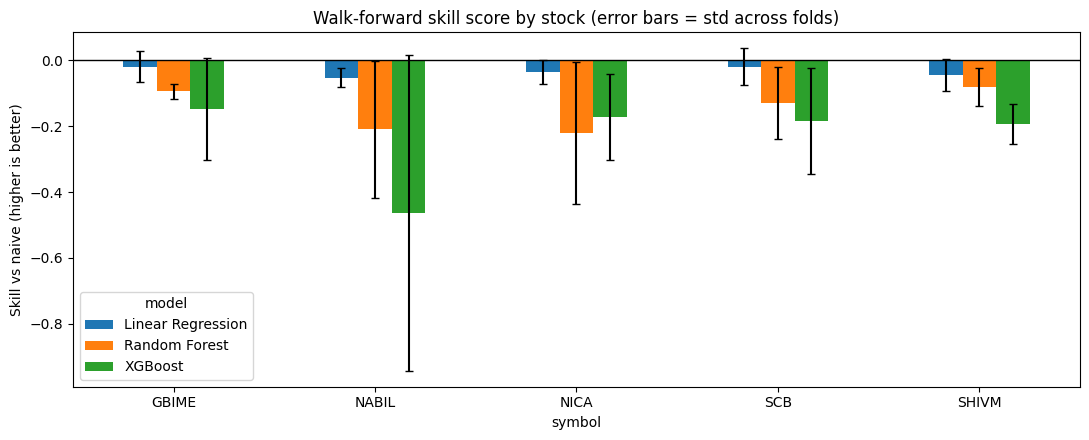

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
skill_mean = summary["mean_skill"].unstack("model")
skill_std = summary["std_skill"].unstack("model")
skill_mean.plot(kind="bar", yerr=skill_std, ax=ax, capsize=3)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Skill vs naive (higher is better)")
ax.set_title("Walk-forward skill score by stock (error bars = std across folds)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Pooled out-of-sample direction accuracy vs the "always up" baseline (moved days only).
rows = []
for sym, s in store.items():
    oos = s["oos"]
    today, actual = oos["today"].to_numpy(), oos["actual"].to_numpy()
    row = {"symbol": sym, "days_moved": f"{(actual != today).mean():.0%}", "always_up": up_share(today, actual)}
    for name in (LIN, RF, XGB):
        row[name] = direction_acc_moved(today, actual, oos[f"p_{name}"].to_numpy())
    rows.append(row)
pd.DataFrame(rows).set_index("symbol").round(3)

,days_moved,always_up,Linear Regression,Random Forest,XGBoost
symbol,,,,,
NABIL,64%,0.481,0.457,0.505,0.519
NICA,66%,0.421,0.457,0.454,0.490
GBIME,65%,0.468,0.519,0.536,0.502
SCB,65%,0.532,0.519,0.485,0.471
SHIVM,66%,0.475,0.528,0.508,0.522


In [14]:
# Final holdout (last fold) including the LSTM.
final_table = pd.concat([s["final_df"].assign(symbol=sym) for sym, s in store.items()], ignore_index=True)
final_table.pivot(index="symbol", columns="model", values="skill").mul(100).round(2)

model,LSTM,Linear Regression,Naive (today = tomorrow),Random Forest,XGBoost
symbol,,,,,
GBIME,0.03,-2.84,0.0,-7.53,-12.66
NABIL,-0.16,-8.36,0.0,-4.12,-11.55
NICA,0.23,-0.70,0.0,-2.86,-4.53
SCB,0.23,-1.53,0.0,-6.37,-7.08
SHIVM,-1.49,-9.85,0.0,-9.03,-25.76


## 7. Backtest with trading costs

Signal: hold the stock for one day if the Linear model predicts a return above the threshold, otherwise stay in cash.
Out-of-sample predictions only. Costs: brokerage and SEBON fee on every buy and sell, capital gains tax on profit.

**Limits:** no slippage, no price limits or illiquidity, DP charge ignored, T+3 settlement ignored.
A real trader could not enter and exit every day at the close price.

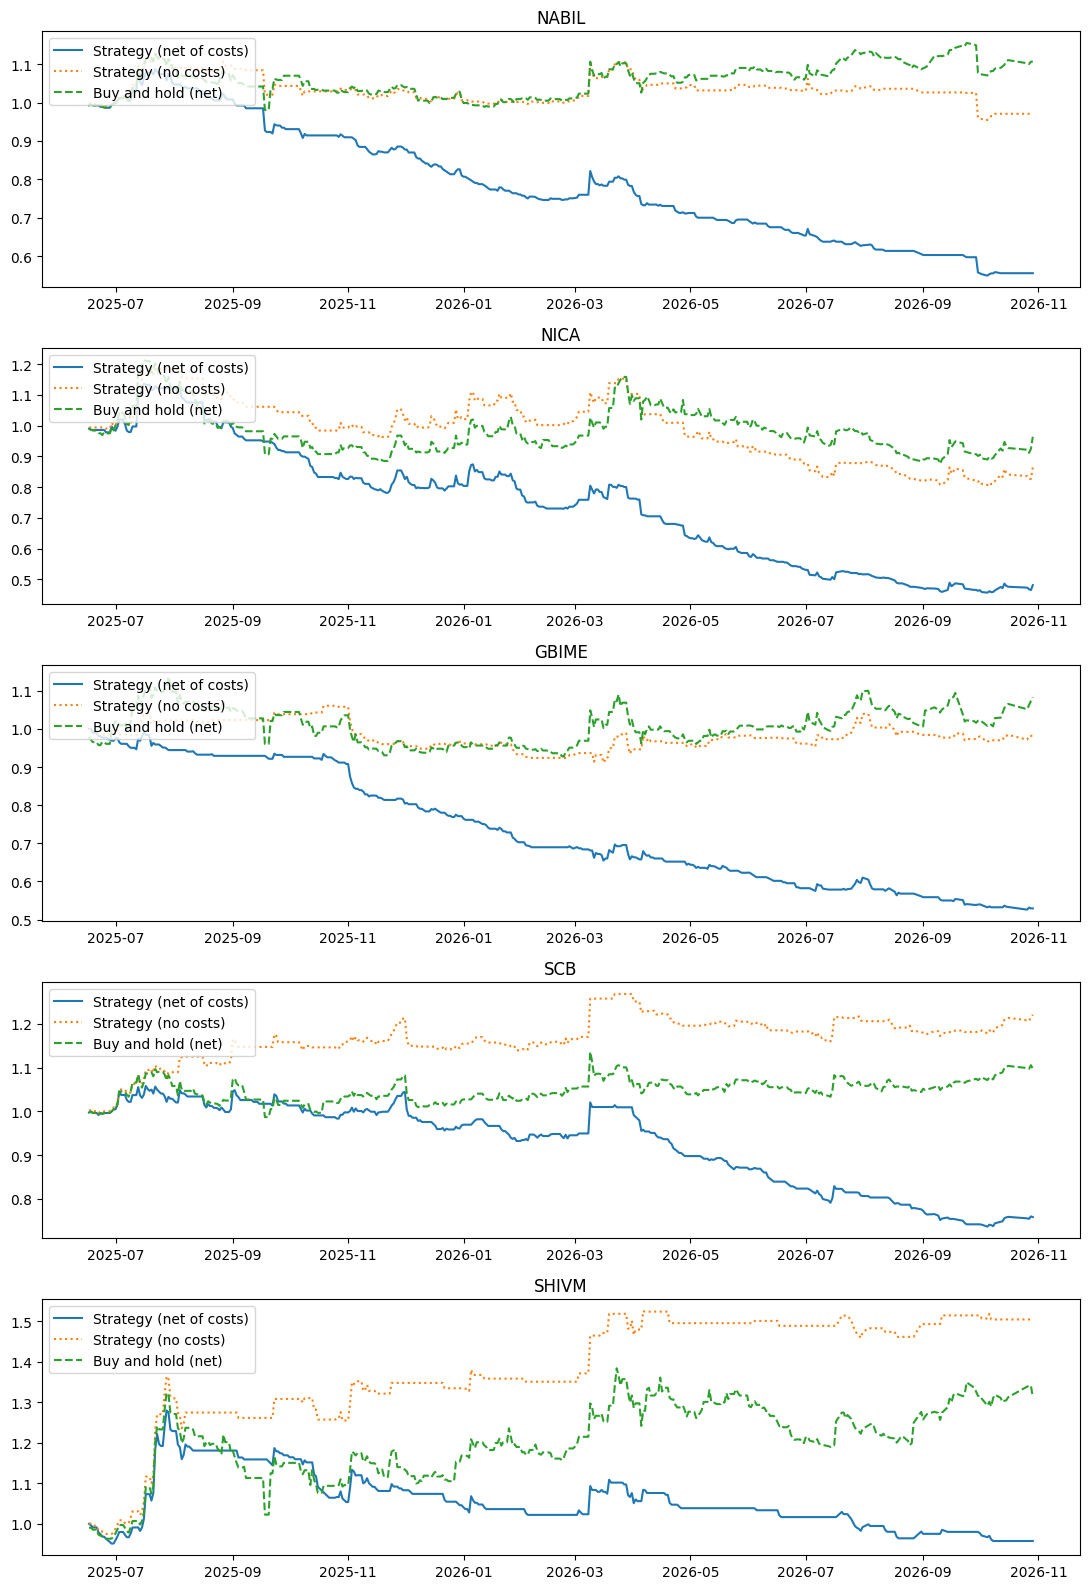

,strategy_net,strategy_gross,buy_hold_net,strategy_max_dd,buy_hold_max_dd,trades,time_in_market
symbol,,,,,,,
NABIL,-0.444,-0.029,0.107,-0.495,-0.129,64,0.541
NICA,-0.519,-0.135,-0.036,-0.598,-0.278,65,0.657
GBIME,-0.471,-0.018,0.083,-0.474,-0.184,71,0.400
SCB,-0.242,0.221,0.097,-0.304,-0.100,54,0.631
SHIVM,-0.042,0.505,0.312,-0.252,-0.227,49,0.312


In [15]:
bt_rows, fig_axes = [], plt.subplots(len(store), 1, figsize=(11, 3.2 * len(store)))[1]
fig_axes = np.atleast_1d(fig_axes)

for ax, (sym, s) in zip(fig_axes, store.items()):
    oos = s["oos"]
    today, actual = oos["today"].to_numpy(), oos["actual"].to_numpy()
    position = (oos[f"r_{LIN}"].to_numpy() > BACKTEST_THRESHOLD).astype(int)
    strat = backtest(today, actual, position)
    hold = backtest(today, actual, np.ones(len(today), dtype=int))

    ax.plot(oos["date"], strat["net_curve"], label="Strategy (net of costs)")
    ax.plot(oos["date"], strat["gross_curve"], label="Strategy (no costs)", linestyle=":")
    ax.plot(oos["date"], hold["net_curve"], label="Buy and hold (net)", linestyle="--")
    ax.set_title(sym)
    ax.legend(loc="upper left")
    bt_rows.append({
        "symbol": sym,
        "strategy_net": strat["net_return"], "strategy_gross": strat["gross_return"],
        "buy_hold_net": hold["net_return"],
        "strategy_max_dd": strat["max_drawdown"], "buy_hold_max_dd": hold["max_drawdown"],
        "trades": strat["trades"], "time_in_market": strat["time_in_market"],
    })
plt.tight_layout()
plt.show()

backtest_table = pd.DataFrame(bt_rows).set_index("symbol")
backtest_table.round(3)

## 8. Feature importance (permutation, final fold)

In [16]:
sym = SYMBOLS[0]
models_last, X_te, y_te = store[sym]["last_models"]
imp = permutation_importance(models_last[XGB], X_te, y_te, n_repeats=5, random_state=RANDOM_SEED,
                             scoring="neg_root_mean_squared_error")
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"{sym}: XGBoost permutation importance (RMSE increase when the feature is shuffled)")
importance.head(8).round(4)

NABIL: XGBoost permutation importance (RMSE increase when the feature is shuffled)


,0
Percent Change,0.0145
EMA_10,0.0054
Close,0.0037
High,0.0029
Open,0.0021
Low,0.0003
Close_lag1,0.0000
10 Day MA,-0.0005


## 9. Conclusion (auto-generated) and exports

In [17]:
lines = ["CONCLUSION", "=" * 60,
         "Skill > 0 means the model beat 'tomorrow = today' on RMSE.", ""]
for sym in SYMBOLS:
    s = summary.loc[sym]
    best = s["mean_skill"].idxmax()
    lines.append(
        f"{sym}: best model {best}, mean skill {s.loc[best, 'mean_skill']:+.1%}, "
        f"beat naive in {int(s.loc[best, 'folds_beating_naive'])}/{N_FOLDS} folds."
    )

positive = int((summary["mean_skill"] > 0).sum())
lines += ["", f"Model-stock pairs with positive mean skill: {positive} of {len(summary)}."]

beats_bh = int((backtest_table["strategy_net"] > backtest_table["buy_hold_net"]).sum())
lines.append(f"Strategy beat buy-and-hold after costs on {beats_bh} of {len(backtest_table)} stocks.")
lines.append(f"Average net strategy return: {backtest_table['strategy_net'].mean():+.1%} "
             f"(no costs: {backtest_table['strategy_gross'].mean():+.1%}).")
lines += ["", "Treat positive results with care: small samples, no slippage, no liquidity limits.",
          "Not financial advice."]
print("\n".join(lines))

fold_results.to_csv("results_walk_forward.csv", index=False)
summary.to_csv("results_summary.csv")
backtest_table.to_csv("results_backtest.csv")
Path("conclusion.txt").write_text("\n".join(lines), encoding="utf-8")

CONCLUSION
Skill > 0 means the model beat 'tomorrow = today' on RMSE.

NABIL: best model Linear Regression, mean skill -5.3%, beat naive in 0/5 folds.
NICA: best model Linear Regression, mean skill -3.4%, beat naive in 1/5 folds.
GBIME: best model Linear Regression, mean skill -1.9%, beat naive in 1/5 folds.
SCB: best model Linear Regression, mean skill -1.9%, beat naive in 2/5 folds.
SHIVM: best model Linear Regression, mean skill -4.4%, beat naive in 1/5 folds.

Model-stock pairs with positive mean skill: 0 of 15.
Strategy beat buy-and-hold after costs on 0 of 5 stocks.
Average net strategy return: -34.4% (no costs: +10.9%).

Treat positive results with care: small samples, no slippage, no liquidity limits.
Not financial advice.


801

## 10. Save and download

One zip with models, scalers, data, results and conclusion.
- `models/<SYMBOL>.joblib` and `data/<SYMBOL>.csv` go into the FastAPI project.
- Then run `python -m app.loader data/` and start the API.

In [18]:
archive = Path("nepse_artifacts.zip")
extra = [Path("results_walk_forward.csv"), Path("results_summary.csv"),
         Path("results_backtest.csv"), Path("conclusion.txt")]
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in (MODEL_DIR, SCALER_DIR, DATA_DIR):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                zf.write(path)
    for path in extra:
        if path.exists():
            zf.write(path)
print("Created", archive, f"({archive.stat().st_size / 1e6:.1f} MB)")


def save_with_dialog(archive):
    # Local machine: opens a "Save as" window
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)
    start = Path.home() / "Desktop"
    target = filedialog.asksaveasfilename(
        parent=root, title="Save NEPSE artifacts", initialfile=archive.name,
        initialdir=str(start if start.exists() else Path.home()),
        defaultextension=".zip", filetypes=[("Zip file", "*.zip")],
    )
    root.destroy()
    if not target:
        print("Cancelled. Zip is still at", archive.resolve())
        return
    shutil.copy(archive, target)
    print("Saved to", target)


def save_with_browser_picker(archive):
    # Colab: button that opens the browser's "Save as" window
    b64 = base64.b64encode(archive.read_bytes()).decode()
    page = '''
    <button id="save" style="padding:8px 16px;font-size:14px">Choose where to save</button>
    <span id="msg"></span>
    <script>
    const bytes = Uint8Array.from(atob("__B64__"), c => c.charCodeAt(0));
    document.getElementById("save").onclick = async () => {
      const msg = document.getElementById("msg");
      try {
        const handle = await window.showSaveFilePicker({
          suggestedName: "__NAME__",
          types: [{description: "Zip file", accept: {"application/zip": [".zip"]}}],
        });
        const w = await handle.createWritable();
        await w.write(bytes);
        await w.close();
        msg.textContent = " Saved.";
      } catch (e) {
        if (e.name === "AbortError") { msg.textContent = " Cancelled."; return; }
        const a = document.createElement("a");
        a.href = URL.createObjectURL(new Blob([bytes], {type: "application/zip"}));
        a.download = "__NAME__";
        a.click();
        msg.textContent = " Picker blocked. Normal download started.";
      }
    };
    </script>
    '''
    display(HTML(page.replace("__B64__", b64).replace("__NAME__", archive.name)))


try:
    import google.colab  # noqa: F401
    save_with_browser_picker(archive)
except ImportError:
    try:
        save_with_dialog(archive)
    except Exception as exc:
        print("Could not open the dialog:", exc)
        print("Zip is at", archive.resolve())

Created nepse_artifacts.zip (5.6 MB)
